In [ ]:
from google.colab import userdata
import os, json

# 1. Write kaggle.json from your Secrets (no key visible in the code)
os.makedirs("/root/.kaggle", exist_ok=True)

token = {
    "username": userdata.get("KAGGLE_USERNAME"),
    "key": userdata.get("KAGGLE_KEY"),
}

with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(token, f)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

# 2. Download only if the data is not already there
if os.path.exists("/content/data/archive/train"):
    print("Data already exists, skipping download")
else:
    !kaggle datasets download -d uashutoshk/nepali-currency-dataset -p /content/data --unzip

# 3. Check
!ls /content/data/archive

Data already exists, skipping download
train  validate


In [ ]:
!kaggle datasets download -d uashutoshk/nepali-currency-dataset -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/uashutoshk/nepali-currency-dataset
License(s): unknown
100% 6.36G/6.36G [06:03<00:00, 18.8MB/s]



In [ ]:
!ls /content/data

archive


In [ ]:
!ls -la /content/data
!ls /content/data/archive | head

total 12
drwxr-xr-x 3 root root 4096 Oct 13 09:32 .
drwxr-xr-x 1 root root 4096 Oct 13 09:25 ..
drwxr-xr-x 4 root root 4096 Oct 13 09:32 archive
train
validate


In [ ]:
import os

root = "/content/data"
for dirpath, dirnames, filenames in os.walk(root):
    if filenames:
        print(dirpath, "->", len(filenames), "images")

/content/data/archive/validate/500 -> 581 images
/content/data/archive/validate/10 -> 525 images
/content/data/archive/validate/1000 -> 581 images
/content/data/archive/validate/50 -> 595 images
/content/data/archive/validate/20 -> 430 images
/content/data/archive/validate/100 -> 601 images
/content/data/archive/validate/5 -> 501 images
/content/data/archive/train/500 -> 2597 images
/content/data/archive/train/10 -> 3189 images
/content/data/archive/train/1000 -> 2608 images
/content/data/archive/train/50 -> 2760 images
/content/data/archive/train/20 -> 3079 images
/content/data/archive/train/100 -> 3087 images
/content/data/archive/train/5 -> 1499 images


In [ ]:
import torch
from torch import nn
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(root="/content/data/archive/train", transform=transform)
test_data = datasets.ImageFolder(root="/content/data/archive/validate", transform=transform)

image, label = train_data[0]
print(image.shape)
print(train_data.classes)

torch.Size([3, 128, 128])
['10', '100', '1000', '20', '5', '50', '500']


In [ ]:

from torch.utils.data import TensorDataset

def cache(dataset):
    loader = DataLoader(dataset, batch_size=64, num_workers=2)
    Xs, ys = [], []
    for X, y in tqdm(loader):
        Xs.append(X); ys.append(y)
    return TensorDataset(torch.cat(Xs), torch.cat(ys))

train_cached = cache(train_data)   # slow once
test_cached = cache(test_data)

train_loader = DataLoader(train_cached, batch_size=32, shuffle=True)
test_loader = DataLoader(test_cached, batch_size=32, shuffle=False)

  0%|          | 0/295 [00:00<?, ?it/s]

  0%|          | 0/60 [00:00<?, ?it/s]

In [ ]:
from torch.utils.data import Dataset

aug = transforms.Compose([
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(128, scale=(0.6, 1.0)),
])

class AugDataset(Dataset):
    def __init__(self, base): self.base = base
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        x, y = self.base[i]
        return aug(x), y

train_loader = DataLoader(AugDataset(train_cached), batch_size=32, shuffle=True)
test_loader = DataLoader(test_cached, batch_size=32, shuffle=False)

In [ ]:
class CurrencyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.block_1 = block(3, 16)
        self.block_2 = block(16, 32)
        self.block_3 = block(32, 64)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64 * 16 * 16, 7),
        )

    def forward(self, x):
        return self.classifier(self.block_3(self.block_2(self.block_1(x))))

model = CurrencyCNN().to(device)


In [ ]:
dummy = torch.randn(1, 3, 128, 128).to(device)
print(model(dummy).shape)

torch.Size([1, 7])


In [ ]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model.parameters(), lr=0.0003)

def accuracy_fn(y_true, y_pred):
    correct = (y_true == y_pred).sum().item()
    return (correct / len(y_pred)) * 100

In [ ]:
def train_step(model, data_loader, loss_fn, optimizer, accuracy_fn, device):
    train_loss, train_acc = 0, 0
    model.train()
    for X, y in data_loader:
        X, y = X.to(device), y.to(device)

        y_logits = model(X)                      # 1. Forward
        loss = loss_fn(y_logits, y)              # 2. Loss
        train_loss += loss.item()
        y_pred = y_logits.argmax(dim=1)
        train_acc += accuracy_fn(y, y_pred)

        optimizer.zero_grad()                    # 3. Zero
        loss.backward()                          # 4. Backward
        optimizer.step()                         # 5. Step

    train_loss /= len(data_loader)
    train_acc /= len(data_loader)
    print(f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.2f}%")
    return train_loss, train_acc


def test_step(model, data_loader, loss_fn, accuracy_fn, device):
    test_loss, test_acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            y_logits = model(X)
            test_loss += loss_fn(y_logits, y).item()
            test_acc += accuracy_fn(y, y_logits.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f"Test loss: {test_loss:.4f} | Test acc: {test_acc:.2f}%\n")
    return test_loss, test_acc

In [ ]:
from tqdm.auto import tqdm

epochs = 15

for epoch in tqdm(range(epochs)):
    print(f"Epoch {epoch + 1}/{epochs}")
    train_step(model, train_loader, loss_fn, optimizer, accuracy_fn, device)
    test_step(model, test_loader, loss_fn, accuracy_fn, device)

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15
Train loss: 1.3330 | Train acc: 55.99%
Test loss: 0.9824 | Test acc: 63.96%

Epoch 2/15
Train loss: 0.5028 | Train acc: 82.09%
Test loss: 0.5234 | Test acc: 82.15%

Epoch 3/15
Train loss: 0.3528 | Train acc: 88.10%
Test loss: 0.6398 | Test acc: 74.62%

Epoch 4/15
Train loss: 0.2353 | Train acc: 92.28%
Test loss: 0.6485 | Test acc: 76.98%

Epoch 5/15
Train loss: 0.1911 | Train acc: 93.71%
Test loss: 0.7640 | Test acc: 77.06%

Epoch 6/15
Train loss: 0.2542 | Train acc: 91.88%
Test loss: 0.2433 | Test acc: 92.14%

Epoch 7/15
Train loss: 0.1416 | Train acc: 95.43%
Test loss: 0.3071 | Test acc: 90.49%

Epoch 8/15
Train loss: 0.1568 | Train acc: 95.00%
Test loss: 0.8016 | Test acc: 77.78%

Epoch 9/15
Train loss: 0.1975 | Train acc: 93.63%
Test loss: 0.3222 | Test acc: 91.15%

Epoch 10/15
Train loss: 0.1387 | Train acc: 95.58%
Test loss: 0.1600 | Test acc: 94.56%

Epoch 11/15
Train loss: 0.0811 | Train acc: 97.48%
Test loss: 0.2958 | Test acc: 92.37%

Epoch 12/15
Train loss: 0.0781

['10', '100', '1000', '20', '5', '50', '500']


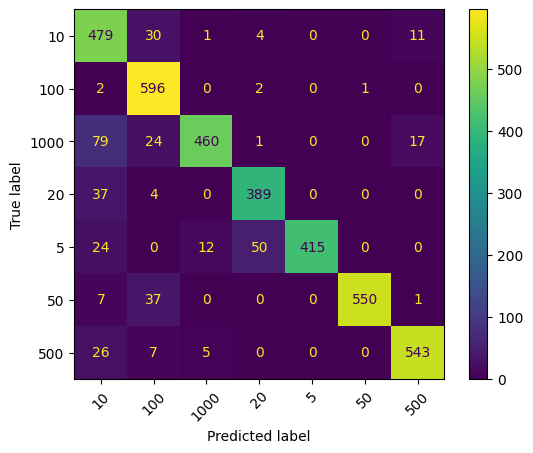

train: Counter({0: 3189, 1: 3087, 3: 3079, 5: 2760, 2: 2608, 6: 2597, 4: 1499})
val:   Counter({1: 601, 5: 595, 2: 581, 6: 581, 0: 525, 4: 501, 3: 430})


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()
preds, truth = [], []
with torch.inference_mode():
    for X, y in test_loader:
        preds += model(X.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()

print(train_data.classes)
cm = confusion_matrix(truth, preds)
ConfusionMatrixDisplay(cm, display_labels=train_data.classes).plot(xticks_rotation=45)
plt.show()

import collections
print("train:", collections.Counter(train_data.targets))
print("val:  ", collections.Counter(test_data.targets))